<a href="https://colab.research.google.com/github/cahyaikhsani/Portofolio/blob/main/Tugas_2_Supervised.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# BAGIAN 1 · Import library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, RocCurveDisplay


In [2]:
# BAGIAN 2 · Muat dataset
df = pd.read_csv("dataset_risiko_dropout_mahasiswa.csv")

In [3]:
# BAGIAN 3 · Kenali data (EDA singkat)
print(df.shape)
print(df.head())
print(df.isnull().sum())
print(df["dropout"].value_counts(normalize=True).round(3))
print(df.groupby("status_sosial_ekonomi")["dropout"].mean().round(3))

(5000, 6)
  id_mahasiswa   ipk  kehadiran_persen  umur status_sosial_ekonomi  dropout
0      MHS0001  2.85              86.7    24                Rendah        1
1      MHS0002  3.04              85.8    19              Menengah        0
2      MHS0003  2.59              70.5    24              Menengah        0
3      MHS0004  2.30              84.0    21              Menengah        0
4      MHS0005  2.75              71.2    20              Menengah        0
id_mahasiswa               0
ipk                        0
kehadiran_persen         200
umur                       0
status_sosial_ekonomi      0
dropout                    0
dtype: int64
dropout
0    0.767
1    0.233
Name: proportion, dtype: float64
status_sosial_ekonomi
Menengah    0.176
Rendah      0.391
Tinggi      0.095
Name: dropout, dtype: float64


In [4]:
# BAGIAN 4 · Pilih fitur, bagi data
fitur_angka = ["ipk", "kehadiran_persen", "umur"]
fitur_kategori = ["status_sosial_ekonomi"]
X = df[fitur_angka + fitur_kategori]
y = df["dropout"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(4000, 4) (1000, 4)


In [5]:
# BAGIAN 5 · Preprocessing + model dalam Pipeline
prep = ColumnTransformer([
    ("angka", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), fitur_angka),
    ("kategori", make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")), fitur_kategori),
])
model = make_pipeline(prep, LogisticRegression(C=1.0, max_iter=1000))
model.fit(X_train, y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('angka',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  ['ipk', 'kehadiran_persen',
                                                   'umur']),
                                                 ('kategori',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehotencoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['status_sosial_ekonomi'])])),
                ('logisticregression', LogisticRegression(max_iter=1000))])

Akurasi uji : 0.824
F1 (macro)  : 0.723
              precision    recall  f1-score   support

           0       0.85      0.93      0.89       767
           1       0.67      0.47      0.56       233

    accuracy                           0.82      1000
   macro avg       0.76      0.70      0.72      1000
weighted avg       0.81      0.82      0.81      1000



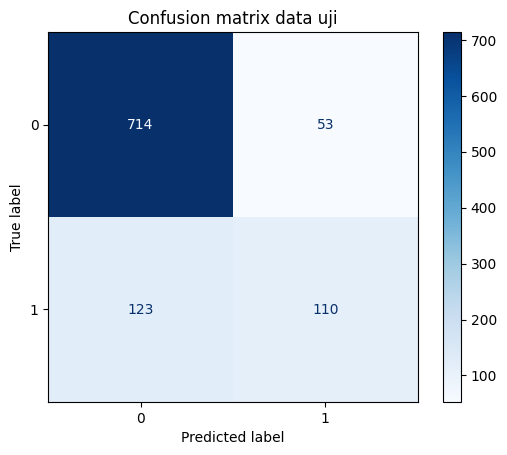

ROC-AUC: 0.853


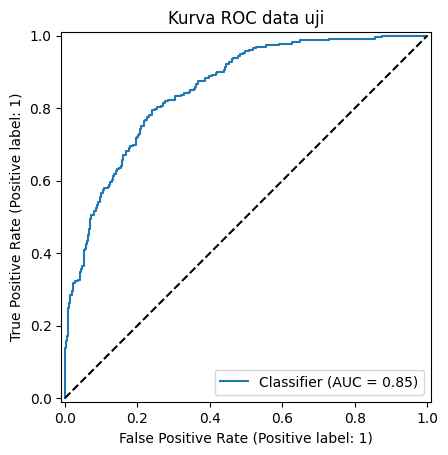

Akurasi CV 5-fold: 0.827 ± 0.012


In [6]:
# BAGIAN 6 · Evaluasi model
y_pred = model.predict(X_test)
print("Akurasi uji :", round(accuracy_score(y_test, y_pred), 3))
print("F1 (macro)  :", round(f1_score(y_test, y_pred, average="macro"), 3))
print(classification_report(y_test, y_pred))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("Confusion matrix data uji")
plt.show()
# ROC-AUC · kemampuan memisahkan kelas di semua threshold
kelas = model.classes_
skor = model.predict_proba(X_test) if hasattr(model, "predict_proba") else model.decision_function(X_test)
if len(kelas) == 2:
    skor_pos = skor[:, 1] if skor.ndim == 2 else skor
    print("ROC-AUC:", round(roc_auc_score(y_test, skor_pos), 3))
    RocCurveDisplay.from_predictions(y_test, skor_pos, pos_label=kelas[1])
else:
    print("ROC-AUC (one-vs-rest, rata-rata):", round(roc_auc_score(y_test, skor, multi_class="ovr"), 3))
    fig, ax = plt.subplots()
    for i, k in enumerate(kelas):
        RocCurveDisplay.from_predictions(y_test == k, skor[:, i], name=f"kelas {k}", ax=ax)
plt.plot([0, 1], [0, 1], "k--")
plt.title("Kurva ROC data uji")
plt.show()
skor_cv = cross_val_score(model, X_train, y_train, cv=5)
print("Akurasi CV 5-fold:", skor_cv.mean().round(3), "±", skor_cv.std().round(3))

ROC-AUC: 0.853


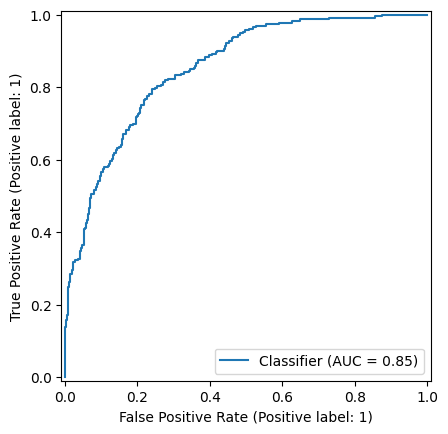

threshold 0.3: akurasi = 0.787
threshold 0.5: akurasi = 0.824
threshold 0.7: akurasi = 0.822


In [7]:
# BAGIAN 7 · Peluang, ROC-AUC, threshold
p = model.predict_proba(X_test)[:, 1]
print("ROC-AUC:", round(roc_auc_score(y_test, p), 3))
RocCurveDisplay.from_predictions(y_test, p)
plt.show()
for t in [0.3, 0.5, 0.7]:
    print(f"threshold {t}: akurasi = {accuracy_score(y_test, (p >= t).astype(int)):.3f}")

In [8]:
# BAGIAN 8 · Membaca koefisien
nama = model[0].get_feature_names_out()
koef = pd.Series(model[-1].coef_[0], index=nama).sort_values()
print(koef.round(2))

angka__ipk                                 -1.19
kategori__status_sosial_ekonomi_Tinggi     -0.62
angka__kehadiran_persen                    -0.58
kategori__status_sosial_ekonomi_Menengah   -0.18
angka__umur                                 0.27
kategori__status_sosial_ekonomi_Rendah      0.79
dtype: float64
